# Generate the simulation count tensors

Reconstruct the fixed-start synthetic inputs used by the manuscript benchmark. Each tensor has clone × time × state axes. The deterministic expected counts are rounded once for the clean realization. Relative Gaussian count variation acts only after the first timepoint; uniform redistribution follows it and preserves each clone-time total.

This walkthrough creates nine representative input conditions and checks their structural invariants. It does not fit partitions, estimate accuracy, or rerun the historical benchmark grid. The historical result notebooks provide the retained Monte Carlo accuracy estimates.

**Environment:** `chronoclone`, `/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone-paper`. Versions and the active interpreter are printed below. A reader can use the recorded environment specification and another local path.

**Execute from this module's root:**
```sh
python -m nbconvert --execute --to notebook --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper notebooks/0002_noise_generation.ipynb
```

**Generate another configured condition:**
```sh
python scripts/generate_counts.py --gaussian 20 --uniform 40 --repeat 7 --output results/reproduced_tensors/g020_u040_r007.npz
```

The CLI discovers the adjacent frozen runtime, verifies all scientific source hashes and dependency versions, and refuses to overwrite an existing tensor. Supply `--benchmark-root` only when the frozen runtime is elsewhere.


This execution uses the existing **chronoclone** micromamba environment at `/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. Exact MacBook command:
```bash
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/ChronoClone_paper/benchmarks/run_notebook.py /path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/notebooks/0002_noise_generation.ipynb --kernel chronoclone-paper
```

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import hashlib, importlib.metadata, importlib.util, json, os, platform, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
candidates=[Path.cwd(), *Path.cwd().parents]
MODULE=next(path for path in candidates if (path/'scripts/generate_counts.py').is_file())
spec=importlib.util.spec_from_file_location('count_generation',MODULE/'scripts/generate_counts.py')
generation=importlib.util.module_from_spec(spec);spec.loader.exec_module(generation)
BENCHMARK_ROOT=generation.locate_benchmark_root()
RESULTS=MODULE/'results/reproduced_tensors';RESULTS.mkdir(parents=True,exist_ok=True)
FIGURES=MODULE/'figures/count_generation';FIGURES.mkdir(parents=True,exist_ok=True)
environment={'name':'chronoclone','path':str(Path(sys.executable).parent.parent),'interpreter':sys.executable,
 'kernel':'chronoclone-paper','python':platform.python_version(),
 'versions':{name:importlib.metadata.version(name) for name in ['numpy','pandas','scipy','scikit-learn','matplotlib','nbformat','nbclient']}}
print(json.dumps(environment,indent=2))

{
  "name": "chronoclone",
  "path": "/path/to/ChronoClone/.runtime/chronoclone",
  "interpreter": "/path/to/ChronoClone/.runtime/chronoclone/bin/python",
  "kernel": "chronoclone-paper",
  "python": "3.11.15",
  "versions": {
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "scipy": "1.17.1",
    "scikit-learn": "1.9.0",
    "matplotlib": "3.11.0",
    "nbformat": "5.10.4",
    "nbclient": "0.11.0"
  }
}


## Generate the configured count tensors

Use repeat 0 and percentages 0, 50, and 100 on each axis. Random streams are determined by the original master seed, repeat, and noise percentages; worker scheduling does not select the draws. Truth labels identify simulation programs only. Each method would receive the same ordered eligible IDs; no estimator is called here.

In [2]:
conditions=[(gaussian,uniform,0) for gaussian in [0,50,100] for uniform in [0,50,100]]
with generation.frozen_generator(BENCHMARK_ROOT) as context:
    configuration=dict(context['configuration'])
    source_records=dict(context['source_files'])
    with ThreadPoolExecutor(max_workers=3) as workers:
        generated=list(workers.map(lambda condition:generation.generate_condition(context,*condition),conditions))
    serial_arrays,serial_metadata=generation.generate_condition(context,50,50,0)
    generated_by_condition=dict(zip(conditions,generated))
    assert all(np.array_equal(serial_arrays[key],generated_by_condition[(50,50,0)][0][key]) for key in serial_arrays)
    tensor_receipts=[]
    for condition,(arrays,metadata) in zip(conditions,generated):
        gaussian,uniform,repeat=condition
        output=RESULTS/f'g{gaussian:03d}_u{uniform:03d}_r{repeat:03d}.npz'
        if output.exists():
            receipt=json.loads(output.with_suffix('.json').read_text())
            assert generation.sha256(output)==receipt['file_sha256']
            assert receipt['source_files']==metadata['source_files']
            assert receipt['gaussian_seed']==metadata['gaussian_seed'] and receipt['uniform_seed']==metadata['uniform_seed']
            with np.load(output,allow_pickle=False) as stored:
                assert set(stored.files)==set(arrays)
                assert all(np.array_equal(stored[key],arrays[key]) for key in arrays)
        else:
            receipt=generation.save_condition(arrays,metadata,output,BENCHMARK_ROOT)
        tensor_receipts.append(receipt)
summary=pd.DataFrame([{key:receipt[key] for key in ['gaussian_pct','uniform_pct','repeat','gaussian_seed','uniform_seed','eligible_clones','file_bytes']} for receipt in tensor_receipts])
display(summary)

,gaussian_pct,uniform_pct,repeat,gaussian_seed,uniform_seed,eligible_clones,file_bytes
0,0,0,0,15623759289580903208,118676018126520032,517,14587
1,0,50,0,15623759289580903208,13185550243451895114,517,35755
2,0,100,0,15623759289580903208,1831152283239745190,517,33254
3,50,0,0,7120853461056642087,2837486044726075812,515,51155
4,50,50,0,7120853461056642087,2521486557481615397,515,54938
5,50,100,0,7120853461056642087,9081728335198312160,515,52653
6,100,0,0,200219651973730645,2582925913250237028,507,50593
7,100,50,0,200219651973730645,538789002007442302,507,55116
8,100,100,0,200219651973730645,6593382246037684341,507,52932


## Independently verify the generation contract

The checks below derive eligibility directly from the saved counts: allowed first-time states, a gap-free observed prefix of at least two times, and the declared total-count floor. Gaussian variation may remove small later-time counts and therefore change eligibility. Uniform redistribution may populate previously empty states, but it cannot change clone-time totals or eligibility relative to its Gaussian input.

In [3]:
validation_rows=[]
for condition,(arrays,metadata) in zip(conditions,generated):
    counts=arrays['counts'];gaussian_counts=arrays['gaussian_counts'];clean=arrays['clean_counts']
    state_names=arrays['states'].tolist()
    allowed=np.asarray([name in configuration['allowed_start_states'] for name in state_names])
    first_pure=(counts[:,0,allowed].sum(axis=1)>0)&(counts[:,0,~allowed].sum(axis=1)==0)
    present=counts.sum(axis=2)>0
    required_prefix=present[:,:configuration['min_persistence']].all(axis=1)
    gap_free=np.all(present==(np.arange(counts.shape[1])[None,:]<present.sum(axis=1)[:,None]),axis=1)
    independent_mask=first_pure&required_prefix&gap_free&(counts.sum(axis=(1,2))>=configuration['min_total_count'])
    checks={**metadata['checks'],
      'independent_eligibility_agrees':np.array_equal(independent_mask,arrays['eligible_mask']),
      'eligible_ids_order_matches':np.array_equal(arrays['eligible_clone_ids'],arrays['clone_ids'][independent_mask]),
      'all_method_input_id_hashes_equal':len(set(metadata['method_input_clone_ids_sha256'].values()))==1,
      'gaussian_stream_shared_across_uniform_levels':np.array_equal(gaussian_counts,generated_by_condition[(condition[0],0,0)][0]['gaussian_counts'])}
    assert all(checks.values()),(condition,checks)
    validation_rows.extend({'gaussian_pct':condition[0],'uniform_pct':condition[1],'check':name,'passed':bool(passed)} for name,passed in checks.items())
validation=pd.DataFrame(validation_rows)
display(validation.groupby('check',sort=False)['passed'].agg(['count','all']).reset_index())
print('All count-generation checks passed:',bool(validation['passed'].all()))

,check,count,all
0,nonnegative_integer_counts,9,True
1,fixed_t1_after_gaussian,9,True
2,fixed_t1_after_uniform,9,True
3,gaussian_preserves_structural_zeros,9,True
4,uniform_preserves_clone_time_totals,9,True
5,uniform_preserves_eligibility,9,True
6,clean_condition_equals_rounded_reference,1,True
7,independent_eligibility_agrees,9,True
8,eligible_ids_order_matches,9,True
9,all_method_input_id_hashes_equal,9,True


All count-generation checks passed: True


## Inspect one synthetic clone under four conditions

Each plot uses the first neutral clone identifier from the reference tensor. It is a fixed illustrative choice, not an average or a representative draw selected after inspection. The four plots use the same color scale and retain the unchanged first-time row. Full tensors and all nine conditions are available above.

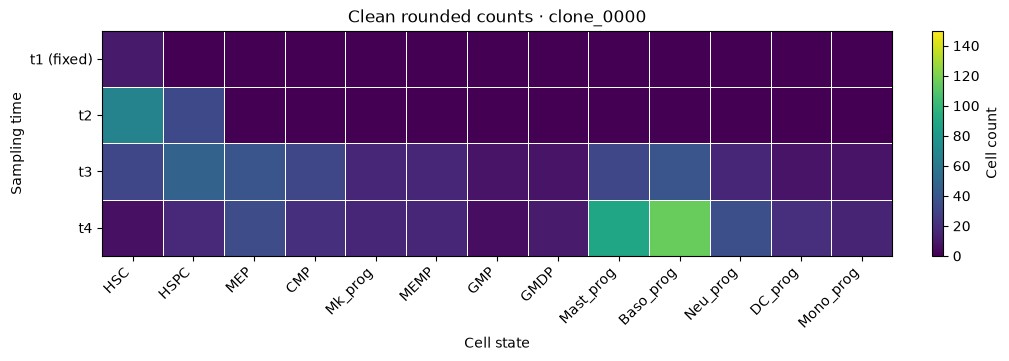

In [4]:
# Plot-specific data selection and common color limits.
arrays=generated_by_condition[(0,0,0)][0]
clone_index=0
matrix=arrays['counts'][clone_index]
comparison_conditions=[(0,0,0),(50,0,0),(0,50,0),(50,50,0)]
vmax=max(float(generated_by_condition[key][0]['counts'][clone_index].max()) for key in comparison_conditions)
with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'svg.fonttype':'none','pdf.fonttype':42}):
    fig,ax=plt.subplots(figsize=(10,3.5),layout='constrained')
    artist=ax.pcolormesh(np.arange(matrix.shape[1]+1),np.arange(matrix.shape[0]+1),matrix,
                        cmap='viridis',vmin=0,vmax=vmax,shading='flat',edgecolors='white',linewidth=.5)
    ax.set_xticks(np.arange(matrix.shape[1])+.5,arrays['states'],rotation=45,ha='right')
    ax.set_yticks(np.arange(matrix.shape[0])+.5,['t1 (fixed)','t2','t3','t4'])
    ax.invert_yaxis();ax.set_xlabel('Cell state');ax.set_ylabel('Sampling time')
    ax.set_title('Clean rounded counts · '+str(arrays['clone_ids'][clone_index]))
    colorbar=fig.colorbar(artist,ax=ax,label='Cell count')
    colorbar.solids.set_rasterized(False)
    fig.savefig(FIGURES/'clean_counts.svg',metadata={'Date':None})
    display(fig)
    plt.close(fig)

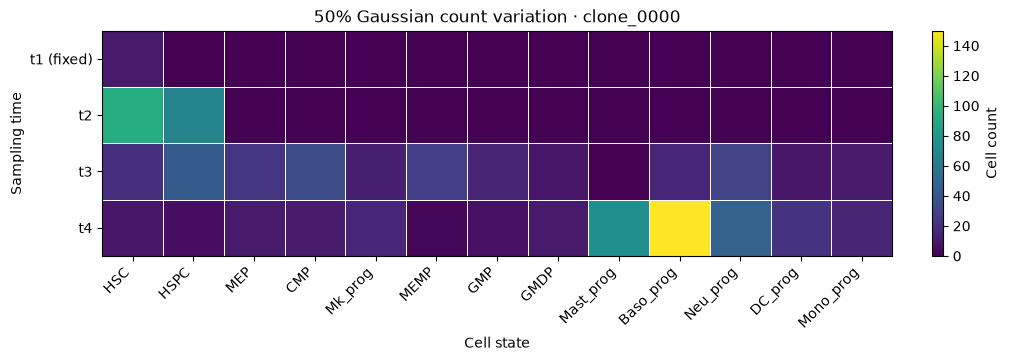

In [5]:
# Plot-specific data selection and common color limits.
arrays=generated_by_condition[(50,0,0)][0]
clone_index=0
matrix=arrays['counts'][clone_index]
comparison_conditions=[(0,0,0),(50,0,0),(0,50,0),(50,50,0)]
vmax=max(float(generated_by_condition[key][0]['counts'][clone_index].max()) for key in comparison_conditions)
with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'svg.fonttype':'none','pdf.fonttype':42}):
    fig,ax=plt.subplots(figsize=(10,3.5),layout='constrained')
    artist=ax.pcolormesh(np.arange(matrix.shape[1]+1),np.arange(matrix.shape[0]+1),matrix,
                        cmap='viridis',vmin=0,vmax=vmax,shading='flat',edgecolors='white',linewidth=.5)
    ax.set_xticks(np.arange(matrix.shape[1])+.5,arrays['states'],rotation=45,ha='right')
    ax.set_yticks(np.arange(matrix.shape[0])+.5,['t1 (fixed)','t2','t3','t4'])
    ax.invert_yaxis();ax.set_xlabel('Cell state');ax.set_ylabel('Sampling time')
    ax.set_title('50% Gaussian count variation · '+str(arrays['clone_ids'][clone_index]))
    colorbar=fig.colorbar(artist,ax=ax,label='Cell count')
    colorbar.solids.set_rasterized(False)
    fig.savefig(FIGURES/'gaussian_counts.svg',metadata={'Date':None})
    display(fig)
    plt.close(fig)

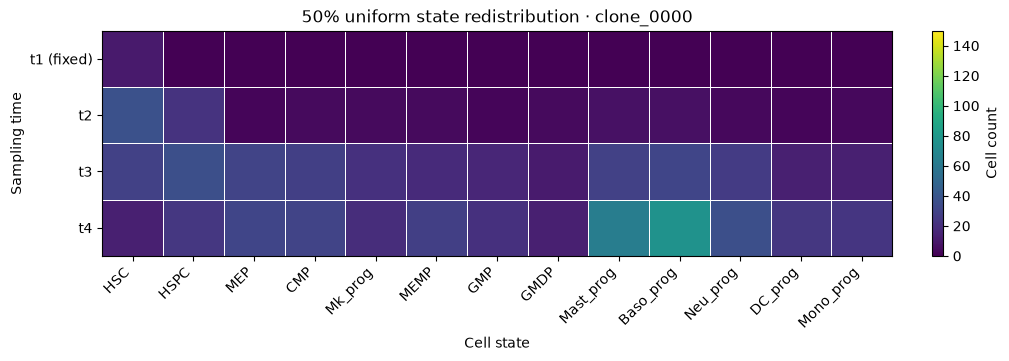

In [6]:
# Plot-specific data selection and common color limits.
arrays=generated_by_condition[(0,50,0)][0]
clone_index=0
matrix=arrays['counts'][clone_index]
comparison_conditions=[(0,0,0),(50,0,0),(0,50,0),(50,50,0)]
vmax=max(float(generated_by_condition[key][0]['counts'][clone_index].max()) for key in comparison_conditions)
with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'svg.fonttype':'none','pdf.fonttype':42}):
    fig,ax=plt.subplots(figsize=(10,3.5),layout='constrained')
    artist=ax.pcolormesh(np.arange(matrix.shape[1]+1),np.arange(matrix.shape[0]+1),matrix,
                        cmap='viridis',vmin=0,vmax=vmax,shading='flat',edgecolors='white',linewidth=.5)
    ax.set_xticks(np.arange(matrix.shape[1])+.5,arrays['states'],rotation=45,ha='right')
    ax.set_yticks(np.arange(matrix.shape[0])+.5,['t1 (fixed)','t2','t3','t4'])
    ax.invert_yaxis();ax.set_xlabel('Cell state');ax.set_ylabel('Sampling time')
    ax.set_title('50% uniform state redistribution · '+str(arrays['clone_ids'][clone_index]))
    colorbar=fig.colorbar(artist,ax=ax,label='Cell count')
    colorbar.solids.set_rasterized(False)
    fig.savefig(FIGURES/'uniform_redistribution_counts.svg',metadata={'Date':None})
    display(fig)
    plt.close(fig)

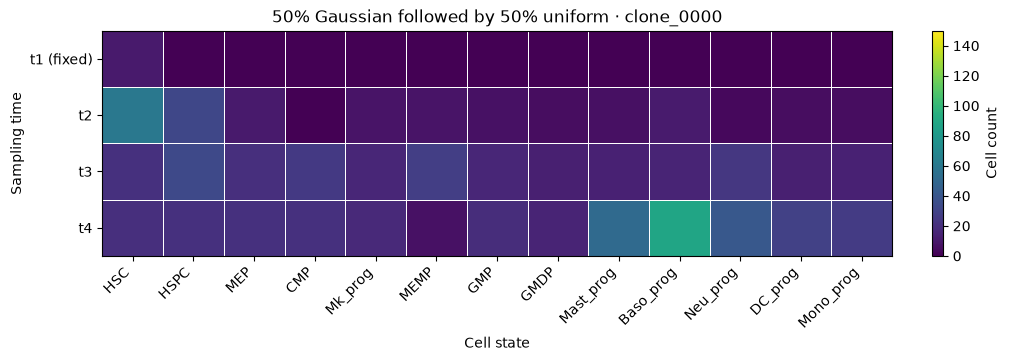

In [7]:
# Plot-specific data selection and common color limits.
arrays=generated_by_condition[(50,50,0)][0]
clone_index=0
matrix=arrays['counts'][clone_index]
comparison_conditions=[(0,0,0),(50,0,0),(0,50,0),(50,50,0)]
vmax=max(float(generated_by_condition[key][0]['counts'][clone_index].max()) for key in comparison_conditions)
with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'svg.fonttype':'none','pdf.fonttype':42}):
    fig,ax=plt.subplots(figsize=(10,3.5),layout='constrained')
    artist=ax.pcolormesh(np.arange(matrix.shape[1]+1),np.arange(matrix.shape[0]+1),matrix,
                        cmap='viridis',vmin=0,vmax=vmax,shading='flat',edgecolors='white',linewidth=.5)
    ax.set_xticks(np.arange(matrix.shape[1])+.5,arrays['states'],rotation=45,ha='right')
    ax.set_yticks(np.arange(matrix.shape[0])+.5,['t1 (fixed)','t2','t3','t4'])
    ax.invert_yaxis();ax.set_xlabel('Cell state');ax.set_ylabel('Sampling time')
    ax.set_title('50% Gaussian followed by 50% uniform · '+str(arrays['clone_ids'][clone_index]))
    colorbar=fig.colorbar(artist,ax=ax,label='Cell count')
    colorbar.solids.set_rasterized(False)
    fig.savefig(FIGURES/'combined_counts.svg',metadata={'Date':None})
    display(fig)
    plt.close(fig)

## Verify the command-line entry point

Reconstruct the combined condition in a temporary output location and compare every saved array with the notebook result. Invalid percentages, repeats, and attempts to overwrite evidence must fail. These checks use no partition fits.

In [8]:
import tempfile
with tempfile.TemporaryDirectory(prefix='chronoclone_generation_check_') as temporary:
    output=Path(temporary)/'combined.npz'
    command=[sys.executable,str(MODULE/'scripts/generate_counts.py'),'--benchmark-root',str(BENCHMARK_ROOT),
             '--gaussian','50','--uniform','50','--repeat','0','--output',str(output)]
    completed=subprocess.run(command,check=True,capture_output=True,text=True,env={**os.environ,'PYTHONDONTWRITEBYTECODE':'1'})
    with np.load(output,allow_pickle=False) as stored:
        assert all(np.array_equal(stored[key],serial_arrays[key]) for key in serial_arrays)
    second=subprocess.run(command,capture_output=True,text=True,env={**os.environ,'PYTHONDONTWRITEBYTECODE':'1'})
    assert second.returncode!=0 and 'existing tensor evidence is never overwritten' in second.stderr
with generation.frozen_generator(BENCHMARK_ROOT) as context:
    rejected=[]
    for bad in [(1,0,0),(0,101,0),(0,0,100),(True,0,0)]:
        try:generation.generate_condition(context,*bad)
        except ValueError:rejected.append(list(bad))
    assert len(rejected)==4
print(json.dumps({'cli_arrays_identical':True,'overwrite_refused':True,'invalid_conditions_refused':rejected},indent=2))

{
  "cli_arrays_identical": true,
  "overwrite_refused": true,
  "invalid_conditions_refused": [
    [
      1,
      0,
      0
    ],
    [
      0,
      101,
      0
    ],
    [
      0,
      0,
      100
    ],
    [
      true,
      0,
      0
    ]
  ]
}


## Optional comparison with the historical repeat-level results

When the registered full aggregate is present, stream it once and compare the reconstructed tensors, eligibility masks, ordered IDs, and random-stream seeds with its matching rows for every method. Summary plotting and generation work without this optional download. This is an identity check against saved inputs, not a new method fit.

In [9]:
aggregate_candidates=[BENCHMARK_ROOT/'results/aggregate/native_method_noise_runs.csv.gz',
                      BENCHMARK_ROOT/'ode_noise/results/aggregate/native_method_noise_runs.csv.gz']
aggregate_path=next((path for path in aggregate_candidates if path.is_file()),None)
historical_comparison={'status':'not_run','reason':'Optional repeat-level aggregate is not present.'}
if aggregate_path is not None:
    expected_asset_sha='e206600a20219a4b8bf11f8213e13ad0909c8ade96c31b33b9c45451d06a984a'
    assert generation.sha256(aggregate_path)==expected_asset_sha
    schema_path=BENCHMARK_ROOT/'frozen_runtime/production/scripts/result_schema.py'
    assert generation.sha256(schema_path)=='660d1df7434b38359e8616275ae227c28c72c0352cd8195d482cec7546959f1e'
    # Independent implementations of the recorded shape/dtype/byte and NUL-delimited string hash contracts.
    def historical_array_hash(array):
        contiguous=np.ascontiguousarray(array);digest=hashlib.sha256()
        digest.update(str(contiguous.dtype).encode('ascii'))
        digest.update(np.asarray(contiguous.shape,dtype=np.int64).tobytes())
        digest.update(contiguous.tobytes())
        return digest.hexdigest()
    def historical_string_hash(values):
        digest=hashlib.sha256()
        for value in values:digest.update(str(value).encode('utf-8')+b'\0')
        return digest.hexdigest()
    expected_by_condition={}
    for condition,(arrays,metadata) in zip(conditions,generated):
        expected_by_condition[condition]={
          'input_tensor_sha256':historical_array_hash(arrays['counts']),
          'eligibility_mask_sha256':historical_array_hash(arrays['eligible_mask'].astype(np.uint8)),
          'eligible_clone_ids_sha256':historical_string_hash(arrays['eligible_clone_ids']),
          'gaussian_seed':f"{metadata['gaussian_seed']:016x}",
          'uniform_seed':f"{metadata['uniform_seed']:016x}",
          'config_sha256':metadata['source_files']['configuration']['sha256']}
    usecols=['gaussian_pct','uniform_pct','repeat','method',*next(iter(expected_by_condition.values())).keys()]
    matched=[]
    for chunk in pd.read_csv(aggregate_path,usecols=usecols,chunksize=50000,
                             dtype={'gaussian_seed':str,'uniform_seed':str}):
        mask=chunk['gaussian_pct'].isin([0,50,100])&chunk['uniform_pct'].isin([0,50,100])&(chunk['repeat']==0)
        matched.extend(chunk.loc[mask].to_dict('records'))
    assert len(matched)==len(conditions)*len(configuration['method_order'])
    for condition in conditions:
        rows=[row for row in matched if (row['gaussian_pct'],row['uniform_pct'],row['repeat'])==condition]
        assert {row['method'] for row in rows}==set(configuration['method_order'])
        for row in rows:
            assert all(row[key]==expected for key,expected in expected_by_condition[condition].items()),row
    historical_comparison={'status':'passed','aggregate_sha256':expected_asset_sha,'matched_rows':len(matched),
      'conditions':len(conditions),'methods':configuration['method_order'],'fields_compared':list(next(iter(expected_by_condition.values())).keys()),
      'expected_inputs':[{'gaussian_pct':key[0],'uniform_pct':key[1],'repeat':key[2],**value} for key,value in expected_by_condition.items()]}
print(json.dumps({key:value for key,value in historical_comparison.items() if key!='expected_inputs'},indent=2))

{
  "status": "passed",
  "aggregate_sha256": "e206600a20219a4b8bf11f8213e13ad0909c8ade96c31b33b9c45451d06a984a",
  "matched_rows": 45,
  "conditions": 9,
  "methods": [
    "ChronoClone",
    "CLADES preprocessing",
    "Cyclone abundance-only",
    "K-means",
    "Ward"
  ],
  "fields_compared": [
    "input_tensor_sha256",
    "eligibility_mask_sha256",
    "eligible_clone_ids_sha256",
    "gaussian_seed",
    "uniform_seed",
    "config_sha256"
  ]
}


## Saved evidence

The tensor metadata records the exact inputs, stream seeds, eligibility, and validation checks. The following receipt binds every NPZ and each editable SVG. These are reconstructed illustrative count inputs; accuracy and uncertainty remain the historical 100-repeat benchmark results.

In [10]:
import xml.etree.ElementTree as ET
figure_records=[]
for path in sorted(FIGURES.glob('*.svg')):
    svg=ET.parse(path)
    images=svg.findall('.//{http://www.w3.org/2000/svg}image')
    texts=svg.findall('.//{http://www.w3.org/2000/svg}text')
    assert not images and texts
    figure_records.append({'file':str(path.relative_to(MODULE)),'sha256':generation.sha256(path),'editable_text_elements':len(texts),'embedded_raster_images':len(images)})
assert len(figure_records)==4
assert all(generation.sha256(BENCHMARK_ROOT/record['path'])==record['sha256'] for record in source_records.values())
receipt={'schema':'chronoclone_count_generation_validation_v1','status':'passed','environment':environment,
 'conditions':summary.to_dict('records'),'validation':validation.to_dict('records'),
 'tensor_files':[{key:item[key] for key in ['file','file_bytes','file_sha256','counts_array_sha256']} for item in tensor_receipts],
 'figures':figure_records,'sources':source_records,'thread_and_serial_arrays_identical':True,
 'cli_arrays_identical':True,'source_files_unchanged':True,'estimator_fits_performed':False,'historical_input_identity':historical_comparison}
(RESULTS/'generation_validation.json').write_text(json.dumps(receipt,indent=2)+'\n')
print(json.dumps({'status':receipt['status'],'tensors':len(tensor_receipts),'checks':len(validation),'editable_figures':len(figure_records),
                  'total_tensor_bytes':sum(item['file_bytes'] for item in tensor_receipts),'estimator_fits_performed':False},indent=2))

{
  "status": "passed",
  "tensors": 9,
  "checks": 91,
  "editable_figures": 4,
  "total_tensor_bytes": 400983,
  "estimator_fits_performed": false
}
